# CODE-M · Day 2 · Hands-on A
## Reconstruct a bacterium by hand: from annotated genome to working model

> **Complete version.** Every task is solved and the outputs are included, for reference and for instructors. Attendees work in the *student* version.

In the talk you met the five questions every reconstruction has to answer. In this session (09:45–12:00, with a short break) you will answer all five for a very small organism, building the model yourself with cobrapy. This afternoon ModelSEED will do the same thing automatically for three real bacteria, and you will know exactly what it is doing under the hood.

**Our organism.** *Toybacter fermentans* is a fictional anaerobic gut bacterium. Its genome has been sequenced and annotated. It ferments glucose to a mixture of acids and ethanol, and uses ammonium as its nitrogen source. Its metabolism is tiny, but its chemistry is real: every metabolite has its true formula and charge, and every reaction balances every atom and every charge, as in the models you downloaded from BiGG.

| Section | Reconstruction question | Time |
|---|---|---|
| 0 · Setup | | 5 min |
| 1 · The annotated genome | *Annotation:* what does each gene do? | 10 min |
| 2 · One reaction by hand | | 10 min |
| 3 · From annotation to a draft | *Annotation:* which reactions, which genes? | 20 min |
| 4 · Exchanges and medium | *Compartments:* what crosses the membrane? | 10 min |
| 5 · Biomass and maintenance | *Biomass:* what is the cell made of? | 10 min |
| 6 · Quality control | *Stoichiometry:* balanced? any dead ends? | 20 min |
| 7 · First simulation, gap-filling | *Gaps:* can it actually grow? | 15 min |
| 8 · Validation against experiments | | 15 min |
| 9 · Visualise · 10 · Save | | 10 min |

**How to use this notebook**
- Run the cells in order with **Shift + Enter**.
- ✍️ marks a task for you: replace each `...` with your code.
- ✅ marks a checkpoint: if it prints a green tick, carry on. If it raises an error, the message tells you what to look at.
- 💬 marks a question to discuss with your neighbour.
- Short of time? Section 8.3 and the extension at the end are optional.

## 0 · Setup  ·  5 min
Run this cell to load the tools. The file `toy_helpers.py`, in the same folder as this notebook, only contains plotting code; you don't need to open it.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # keep the output tidy

import pandas as pd
import cobra
from cobra import Model, Metabolite, Reaction
from cobra.flux_analysis import gapfill, find_blocked_reactions, single_gene_deletion, pfba

from toy_helpers import draw_network          # static drawings of our toy network

cobra.Configuration().processes = 1           # our model is tiny: no need for parallel workers
pd.set_option("display.max_colwidth", 100)
print("cobrapy", cobra.__version__, "| LP solver:", cobra.Configuration().solver.__name__.split("_")[0].split(".")[-1])

cobrapy 0.29.0 | LP solver: glpk


## 1 · The starting point: an annotated genome  ·  10 min

Every reconstruction starts from a **genome annotation**: a predicted function for each gene. Enzymes are labelled with an **EC number** (Enzyme Commission; `EC 1.1.1.27` is L-lactate dehydrogenase). Transporters are labelled with a **TC number** (Transporter Classification). Real annotations come from tools such as Prokka, RAST or eggNOG-mapper and cover thousands of genes. *Toybacter*'s has 21.

In [2]:
GENOME = pd.DataFrame([
    ("TF_0001", "glcP", "glucose permease",                          "TC 2.A.1.1"),
    ("TF_0002", "pfkA", "6-phosphofructokinase",                     "EC 2.7.1.11"),
    ("TF_0003", "gapA", "glyceraldehyde-3-phosphate dehydrogenase",  "EC 1.2.1.12"),
    ("TF_0004", "pykF", "pyruvate kinase",                           "EC 2.7.1.40"),
    ("TF_0005", "ldh",  "L-lactate dehydrogenase",                   "EC 1.1.1.27"),
    ("TF_0006", "lctP", "L-lactate:H+ symporter",                    "TC 2.A.14"),
    ("TF_0007", "pflB", "pyruvate formate-lyase",                    "EC 2.3.1.54"),
    ("TF_0008", "pflA", "pyruvate formate-lyase activating enzyme",  "EC 1.97.1.4"),
    ("TF_0009", "focA", "formate transporter",                       "TC 1.A.16"),
    ("TF_0010", "pta",  "phosphate acetyltransferase",               "EC 2.3.1.8"),
    ("TF_0011", "ackA", "acetate kinase",                            "EC 2.7.2.1"),
    ("TF_0012", "ackB", "acetate kinase",                            "EC 2.7.2.1"),
    ("TF_0013", "actP", "acetate:H+ symporter",                      "TC 2.A.21"),
    ("TF_0014", "adhE", "aldehyde/alcohol dehydrogenase",            "EC 1.1.1.1"),
    ("TF_0015", "amtB", "ammonium channel",                          "TC 1.A.11"),
    ("TF_0016", "atpA", "ATP synthase subunit alpha",                "EC 7.1.2.2"),
    ("TF_0017", "atpD", "ATP synthase subunit beta",                 "EC 7.1.2.2"),
    ("TF_0018", "",     "hypothetical protein",                      ""),
    ("TF_0019", "",     "hypothetical protein",                      ""),
    ("TF_0020", "rpoB", "DNA-directed RNA polymerase subunit beta",  ""),
    ("TF_0021", "dnaK", "chaperone protein DnaK",                    ""),
], columns=["locus_tag", "gene", "product", "function"])
GENOME

,locus_tag,gene,product,function
0,TF_0001,glcP,glucose permease,TC 2.A.1.1
1,TF_0002,pfkA,6-phosphofructokinase,EC 2.7.1.11
2,TF_0003,gapA,glyceraldehyde-3-phosphate dehydrogenase,EC 1.2.1.12
3,TF_0004,pykF,pyruvate kinase,EC 2.7.1.40
4,TF_0005,ldh,L-lactate dehydrogenase,EC 1.1.1.27
5,TF_0006,lctP,L-lactate:H+ symporter,TC 2.A.14
6,TF_0007,pflB,pyruvate formate-lyase,EC 2.3.1.54
7,TF_0008,pflA,pyruvate formate-lyase activating enzyme,EC 1.97.1.4
8,TF_0009,focA,formate transporter,TC 1.A.16
9,TF_0010,pta,phosphate acetyltransferase,EC 2.3.1.8


There are three kinds of rows here:
- **metabolic genes** with an EC or TC number, the raw material for the model;
- **hypothetical proteins**, which have no known function (real genomes have hundreds of these);
- **non-metabolic genes**, such as RNA polymerase (`rpoB`) and a chaperone (`dnaK`). A metabolic model will never include these.

### The reaction database
The annotation tells us what the enzymes *are*. A reaction database tells us what they *do*. Databases such as **BiGG**, **ModelSEED**, **MetaCyc** and **KEGG** store each reaction's equation together with the EC or TC numbers that catalyse it. Our mini-database, **ToyDB**, has 17 reactions, and *Toybacter* does not have all of them.

The equations use cobrapy's text format: `-->` means irreversible and `<=>` means reversible. Metabolite ids follow BiGG: `glc__D_c` is D-glucose in the cytosol (`_c`), `lac__L_e` is L-lactate outside the cell (`_e`), `h` is a proton (H⁺), `pi` is phosphate and `coa` is coenzyme A.

In [3]:
TOYDB = pd.DataFrame([
    ("GLCt",   "glucose transport (uniport)",       "glc__D_e --> glc__D_c",                                    "TC 2.A.1.1"),
    ("GLYC",   "glycolysis (lumped)",               "glc__D_c + 2 adp_c + 2 pi_c + 2 nad_c --> pyr_c + 2 atp_c + 2 nadh_c + 2 h_c + 2 h2o_c",
                                                                                                                "EC 2.7.1.11; EC 1.2.1.12; EC 2.7.1.40"),
    ("LDH",    "L-lactate dehydrogenase",           "pyr_c + nadh_c + h_c <=> lac__L_c + nad_c",                "EC 1.1.1.27"),
    ("LACt2r", "L-lactate transport (H+ symport)",  "lac__L_e + h_e <=> lac__L_c + h_c",                        "TC 2.A.14"),
    ("PFL",    "pyruvate formate-lyase",            "pyr_c + coa_c --> accoa_c + for_c",                        "EC 2.3.1.54; EC 1.97.1.4"),
    ("FORt2r", "formate transport (H+ symport)",    "for_e + h_e <=> for_c + h_c",                              "TC 1.A.16"),
    ("ACK",    "phosphotransacetylase + acetate kinase (lumped)", "accoa_c + pi_c + adp_c --> ac_c + coa_c + atp_c", "EC 2.3.1.8; EC 2.7.2.1"),
    ("ACt2r",  "acetate transport (H+ symport)",    "ac_e + h_e <=> ac_c + h_c",                                "TC 2.A.21"),
    ("ADH",    "acetaldehyde/alcohol dehydrogenase (lumped)", "accoa_c + 2 nadh_c --> coa_c + etoh_c + 2 nad_c", "EC 1.1.1.1"),
    ("NH4t",   "ammonium transport",                "nh4_e <=> nh4_c",                                          "TC 1.A.11"),
    ("ATPS",   "F-type ATPase (proton pump)",       "atp_c + h2o_c + 3 h_c --> adp_c + pi_c + 4 h_e",           "EC 7.1.2.2"),
    ("ALAD",   "alanine dehydrogenase",             "pyr_c + nh4_c + nadh_c + h_c --> ala__L_c + nad_c + h2o_c", "EC 1.4.1.1"),
    ("H2Ot",   "water diffusion",                   "h2o_e <=> h2o_c",                                          "diffusion"),
    ("ETOHt",  "ethanol diffusion",                 "etoh_c <=> etoh_e",                                        "diffusion"),
    ("PDH",    "pyruvate dehydrogenase",            "pyr_c + coa_c + nad_c --> accoa_c + co2_c + nadh_c",       "EC 1.2.4.1"),
    ("ALATA",  "alanine transaminase",              "pyr_c + glu__L_c --> ala__L_c + akg_c",                    "EC 2.6.1.2"),
    ("CO2t",   "CO2 diffusion",                     "co2_c <=> co2_e",                                          "diffusion"),
], columns=["reaction", "name", "equation", "function"])
TOYDB

,reaction,name,equation,function
0,GLCt,glucose transport (uniport),glc__D_e --> glc__D_c,TC 2.A.1.1
1,GLYC,glycolysis (lumped),glc__D_c + 2 adp_c + 2 pi_c + 2 nad_c --> pyr_c + 2 atp_c + 2 nadh_c + 2 h_c + 2 h2o_c,EC 2.7.1.11; EC 1.2.1.12; EC 2.7.1.40
2,LDH,L-lactate dehydrogenase,pyr_c + nadh_c + h_c <=> lac__L_c + nad_c,EC 1.1.1.27
3,LACt2r,L-lactate transport (H+ symport),lac__L_e + h_e <=> lac__L_c + h_c,TC 2.A.14
4,PFL,pyruvate formate-lyase,pyr_c + coa_c --> accoa_c + for_c,EC 2.3.1.54; EC 1.97.1.4
5,FORt2r,formate transport (H+ symport),for_e + h_e <=> for_c + h_c,TC 1.A.16
6,ACK,phosphotransacetylase + acetate kinase (lumped),accoa_c + pi_c + adp_c --> ac_c + coa_c + atp_c,EC 2.3.1.8; EC 2.7.2.1
7,ACt2r,acetate transport (H+ symport),ac_e + h_e <=> ac_c + h_c,TC 2.A.21
8,ADH,acetaldehyde/alcohol dehydrogenase (lumped),accoa_c + 2 nadh_c --> coa_c + etoh_c + 2 nad_c,EC 1.1.1.1
9,NH4t,ammonium transport,nh4_e <=> nh4_c,TC 1.A.11


Last, the metabolites. Each one has its **full chemical formula** and its **charge**, for the form that dominates at the pH inside a cell (about 7.2), exactly as in BiGG. Pyruvate, for example, is the anion C₃H₃O₃⁻ (charge −1), and ammonium is NH₄⁺. This is why protons (`h`) and water (`h2o`) appear explicitly in the equations: every reaction must balance **every element and the charge**.

In [4]:
METABOLITES = pd.DataFrame([
    ("glc__D", "D-glucose",       "C6H12O6",         0), ("pyr",    "pyruvate",       "C3H3O3",         -1),
    ("lac__L", "L-lactate",       "C3H5O3",         -1), ("accoa",  "acetyl-CoA",     "C23H34N7O17P3S", -4),
    ("coa",    "coenzyme A",      "C21H32N7O16P3S", -4), ("for",    "formate",        "CHO2",           -1),
    ("ac",     "acetate",         "C2H3O2",         -1), ("etoh",   "ethanol",        "C2H6O",           0),
    ("nh4",    "ammonium",        "H4N",             1), ("ala__L", "L-alanine",      "C3H7NO2",         0),
    ("co2",    "CO2",             "CO2",             0), ("glu__L", "L-glutamate",    "C5H8NO4",        -1),
    ("akg",    "2-oxoglutarate",  "C5H4O5",         -2), ("atp",    "ATP",            "C10H12N5O13P3",  -4),
    ("adp",    "ADP",             "C10H12N5O10P2",  -3), ("pi",     "phosphate",      "HO4P",           -2),
    ("nad",    "NAD+",            "C21H26N7O14P2",  -1), ("nadh",   "NADH",           "C21H27N7O14P2",  -2),
    ("h",      "H+",              "H",               1), ("h2o",    "water",          "H2O",             0),
], columns=["id", "name", "formula", "charge"])
METABOLITES

,id,name,formula,charge
0,glc__D,D-glucose,C6H12O6,0
1,pyr,pyruvate,C3H3O3,-1
2,lac__L,L-lactate,C3H5O3,-1
3,accoa,acetyl-CoA,C23H34N7O17P3S,-4
4,coa,coenzyme A,C21H32N7O16P3S,-4
5,for,formate,CHO2,-1
6,ac,acetate,C2H3O2,-1
7,etoh,ethanol,C2H6O,0
8,nh4,ammonium,H4N,1
9,ala__L,L-alanine,C3H7NO2,0


💬 **Before going on:** which genes in the annotation will *not* lead to any reaction? Which ToyDB reactions have no gene in *Toybacter*?

<details><summary><b>Answer</b> (click to expand)</summary>

- `TF_0018` and `TF_0019` (hypothetical: no function to match), `rpoB` and `dnaK` (not metabolic) give no reactions.
- `ALAD`, `PDH` and `ALATA` have no matching EC number in the annotation. `H2Ot`, `ETOHt` and `CO2t` are diffusion: no protein, so no gene at all.

</details>

## 2 · The building blocks: one reaction by hand  ·  10 min

A cobrapy model is a container of `Metabolite` and `Reaction` objects. Genes are created automatically from each reaction's gene rule. Let's create the model and add the first reaction from the annotation: `TF_0001`, the glucose permease, which moves glucose from outside the cell into the cytosol.

In [5]:
model = Model("Toybacter_fermentans")
model.compartments = {"c": "cytosol", "e": "extracellular"}

glc_e = Metabolite("glc__D_e", name="D-glucose", formula="C6H12O6", charge=0, compartment="e")
glc_c = Metabolite("glc__D_c", name="D-glucose", formula="C6H12O6", charge=0, compartment="c")

GLCt = Reaction("GLCt", name="glucose transport (uniport)", lower_bound=0, upper_bound=1000)
GLCt.add_metabolites({glc_e: -1, glc_c: 1})      # negative = consumed, positive = produced
GLCt.gene_reaction_rule = "TF_0001"               # the gene that encodes the permease

model.add_reactions([GLCt])
print(GLCt.id, ":", GLCt.reaction, "| bounds:", GLCt.bounds, "| genes:", [g.id for g in GLCt.genes])
model

GLCt : glc__D_e --> glc__D_c | bounds: (0, 1000) | genes: ['TF_0001']


Name,Toybacter_fermentans
Memory address,7017c85450
Number of metabolites,2
Number of reactions,1
Number of genes,1
Number of groups,0
Objective expression,0
Compartments,"extracellular, cytosol"


In [6]:
# ✅ Checkpoint
assert model.reactions.GLCt.reaction == "glc__D_e --> glc__D_c", f"GLCt is {model.reactions.GLCt.reaction}"
assert model.reactions.GLCt.gene_reaction_rule == "TF_0001", "check the gene rule"
assert model.metabolites.glc__D_c.compartment == "c", "glc__D_c should be in compartment 'c'"
assert model.reactions.GLCt.check_mass_balance() == {}, "the two glucose metabolites should have the same formula and charge"
print("✅ GLCt is correct and balanced")

✅ GLCt is correct and balanced


Things to notice:
- **Direction is set by the bounds.** A lower bound of 0 makes the reaction irreversible; a lower bound of −1000 would make it reversible.
- cobrapy created the **gene** `TF_0001` for us, because it appears in the gene rule.
- `glc__D_e` and `glc__D_c` are two different metabolites: same molecule, different compartment.

## 3 · From annotation to a draft network  ·  20 min

Nobody types in 2,000 reactions by hand. Pipelines link annotation and database automatically, and we'll do the same in a few lines. For each ToyDB reaction:

1. read the EC/TC number(s) it needs;
2. find the genes annotated with each one;
3. build the **gene–protein–reaction (GPR) rule**:
   - several genes with the **same** function are treated as **isozymes**, joined with `or` (any one is enough);
   - **several different** functions needed (an enzyme complex, or a lumped pathway) are joined with `and` (all are needed);
4. if any required function has no gene, the reaction stays out of the draft.

In [7]:
def gpr_from_annotation(functions, genome=GENOME):
    """GPR rule for a ToyDB reaction, or None if a required function has no gene."""
    blocks = []
    for f in functions.split(";"):
        genes = genome.loc[genome["function"] == f.strip(), "locus_tag"].tolist()
        if not genes:
            return None                                   # a required enzyme is missing
        blocks.append(genes[0] if len(genes) == 1 else "(" + " or ".join(genes) + ")")
    return " and ".join(blocks)

DB = TOYDB.set_index("reaction")
for rid in ["LDH", "PFL", "ACK", "ATPS", "ALAD"]:
    print(f"{rid:5s} needs {DB.loc[rid, 'function']:24s} ->  GPR: {gpr_from_annotation(DB.loc[rid, 'function'])}")

LDH   needs EC 1.1.1.27              ->  GPR: TF_0005
PFL   needs EC 2.3.1.54; EC 1.97.1.4 ->  GPR: TF_0007 and TF_0008
ACK   needs EC 2.3.1.8; EC 2.7.2.1   ->  GPR: TF_0010 and (TF_0011 or TF_0012)
ATPS  needs EC 7.1.2.2               ->  GPR: (TF_0016 or TF_0017)
ALAD  needs EC 1.4.1.1               ->  GPR: None


💬 Read the five rules. Which reactions need a complex, which have isozymes, and why does `ALAD` get `None`? One of these rules is wrong. Which one? *Hint: look at the product names in the annotation.*

<details><summary><b>Answer</b> (click to expand)</summary>

- `PFL` needs **two different** functions: pyruvate formate-lyase (`pflB`) *and* the enzyme that activates it (`pflA`), so its rule uses `and`.
- `ACK` combines both: phosphotransacetylase (`pta`) **and** an acetate kinase, which can be **either** `ackA` **or** `ackB` (isozymes).
- `ALAD` needs EC 1.4.1.1, which appears nowhere in the annotation, so it stays out of the draft. Remember this one.
- **`ATPS` is wrong.** `atpA` and `atpD` share an EC number, so our simple rule treated them as isozymes (`or`). Their product names say they are the **alpha and beta subunits** of the same molecular machine: *both* are needed. Subunits that share an EC number are a classic trap for automated pipelines. We fix it below.

</details>

Next, a helper that copies one reaction from ToyDB into a model and fills in each metabolite's name, formula, charge and compartment:

In [8]:
MET = METABOLITES.set_index("id")

def add_from_toydb(model, reaction_id, gpr=""):
    """Copy a reaction (and any new metabolites) from ToyDB into `model`."""
    row = DB.loc[reaction_id]
    reaction = Reaction(reaction_id, name=row["name"])
    model.add_reactions([reaction])
    reaction.build_reaction_from_string(row["equation"], verbose=False)  # also creates missing metabolites
    reaction.gene_reaction_rule = gpr
    for met in reaction.metabolites:                    # fill in what the equation can't tell us
        base, compartment = met.id.rsplit("_", 1)
        met.name, met.formula = MET.loc[base, "name"], MET.loc[base, "formula"]
        met.charge, met.compartment = int(MET.loc[base, "charge"]), compartment
    return reaction

Now build the draft: go through ToyDB and add every reaction that has a GPR. `GLCt` is already in the model.

In [9]:
for rid, row in DB.iterrows():
    gpr = gpr_from_annotation(row["function"])
    if gpr is not None and rid not in model.reactions:
        add_from_toydb(model, rid, gpr)

print(f"Draft: {len(model.reactions)} reactions, {len(model.metabolites)} metabolites, {len(model.genes)} genes")
pd.DataFrame([(r.id, r.reaction, r.gene_reaction_rule) for r in model.reactions],
             columns=["reaction", "equation", "GPR"])

Draft: 11 reactions, 22 metabolites, 17 genes


,reaction,equation,GPR
0,GLCt,glc__D_e --> glc__D_c,TF_0001
1,GLYC,2.0 adp_c + glc__D_c + 2.0 nad_c + 2.0 pi_c --> 2.0 atp_c + 2.0 h2o_c + 2.0 h_c + 2.0 nadh_c + p...,TF_0002 and TF_0003 and TF_0004
2,LDH,h_c + nadh_c + pyr_c <=> lac__L_c + nad_c,TF_0005
3,LACt2r,h_e + lac__L_e <=> h_c + lac__L_c,TF_0006
4,PFL,coa_c + pyr_c --> accoa_c + for_c,TF_0007 and TF_0008
5,FORt2r,for_e + h_e <=> for_c + h_c,TF_0009
6,ACK,accoa_c + adp_c + pi_c --> ac_c + atp_c + coa_c,TF_0010 and (TF_0011 or TF_0012)
7,ACt2r,ac_e + h_e <=> ac_c + h_c,TF_0013
8,ADH,accoa_c + 2.0 nadh_c --> coa_c + etoh_c + 2.0 nad_c,TF_0014
9,NH4t,nh4_e <=> nh4_c,TF_0015


In [10]:
# ✅ Checkpoint
assert len(model.reactions) == 11, f"expected 11 reactions in the draft, found {len(model.reactions)}"
assert "ALAD" not in model.reactions and "ETOHt" not in model.reactions
print("✅ Draft network: 11 reactions with genetic evidence")

✅ Draft network: 11 reactions with genetic evidence


### Curation 1: subunits are not isozymes
✍️ Correct the gene rule of `ATPS`: both subunits, `TF_0016` (alpha) and `TF_0017` (beta), are needed.

In [11]:
model.reactions.ATPS.gene_reaction_rule = "TF_0016 and TF_0017"
print("ATPS:", model.reactions.ATPS.gene_reaction_rule)

ATPS: TF_0016 and TF_0017


In [12]:
# ✅ Checkpoint
assert model.reactions.ATPS.gene_reaction_rule == "TF_0016 and TF_0017", model.reactions.ATPS.gene_reaction_rule
print("✅ ATP synthase now needs both of its subunits")

✅ ATP synthase now needs both of its subunits


Locus tags are hard to read, so let's attach the gene names from the annotation. Then draw what we have. The drawing leaves out the small "currency" metabolites (ATP, NADH, CoA, H⁺, water, phosphate) to stay readable.

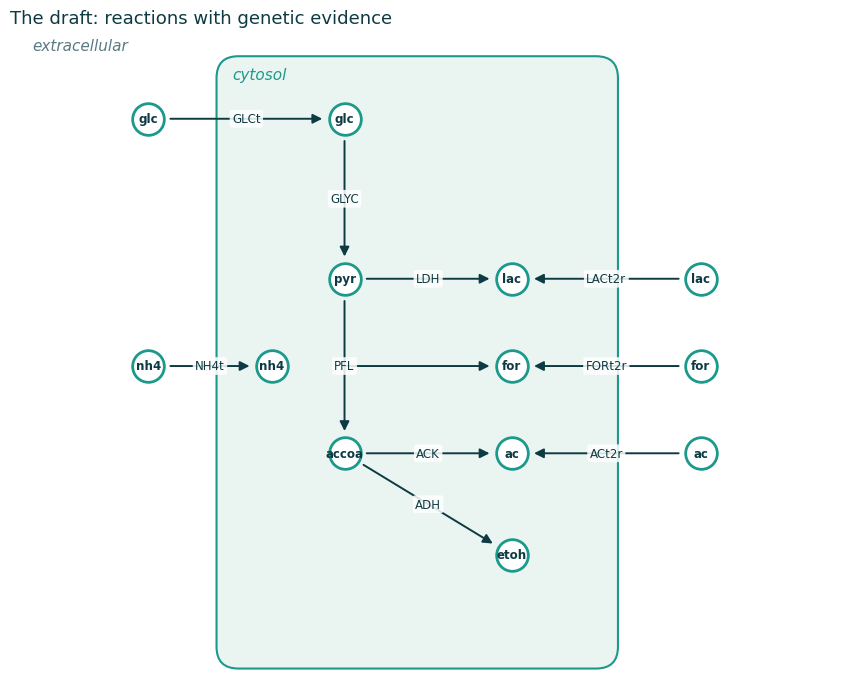

In [13]:
locus_to_name = GENOME.set_index("locus_tag")["gene"]
for gene in model.genes:
    gene.name = locus_to_name[gene.id]

draw_network(model, title="The draft: reactions with genetic evidence");

💬 Look at the drawing. Could this network grow? List what is missing.

<details><summary><b>Answer</b> (click to expand)</summary>

- Nothing can enter or leave the system: there are **no exchange reactions** (§4).
- There is **no biomass reaction**, so nothing for the cell to grow into (§5).
- Ethanol is made inside the cell but **cannot get out**: its diffusion has no gene (§6).
- **No reaction makes alanine** (§6–7).

</details>

## 4 · Compartments and the boundary: exchanges and medium  ·  10 min

The draft has two compartments, cytosol (`c`) and extracellular space (`e`), linked by transport reactions. Notice that the acids (lactate, formate, acetate) cross the membrane **together with a proton** (H⁺ symport), so protons exist outside the cell too.

But the system is closed. FBA assumes steady state, so every extracellular metabolite needs an **exchange reaction** to let it enter or leave. By convention an exchange is written `glc__D_e <=>`: **negative flux means uptake, positive flux means secretion.**

In [14]:
for met in model.metabolites.query(lambda m: m.compartment == "e"):
    model.add_boundary(met, type="exchange", lb=0)       # lb = 0: secretion only, for now

pd.DataFrame([(r.id, r.reaction, r.bounds) for r in model.exchanges], columns=["exchange", "equation", "bounds"])

,exchange,equation,bounds
0,EX_glc__D_e,glc__D_e -->,"(0, 1000.0)"
1,EX_lac__L_e,lac__L_e -->,"(0, 1000.0)"
2,EX_h_e,h_e -->,"(0, 1000.0)"
3,EX_for_e,for_e -->,"(0, 1000.0)"
4,EX_ac_e,ac_e -->,"(0, 1000.0)"
5,EX_nh4_e,nh4_e -->,"(0, 1000.0)"


Cells live in water, and water is made and used by many reactions (look at `GLYC` and `ATPS`). Water crosses membranes by **passive diffusion**: no transporter protein, so **no gene**, which is why the annotation couldn't give us this reaction. We add it by hand, together with an exchange for extracellular water.

In [15]:
add_from_toydb(model, "H2Ot")                                         # diffusion: no gene
model.add_boundary(model.metabolites.h2o_e, type="exchange", lb=0)
print(model.reactions.H2Ot.reaction, "| GPR:", repr(model.reactions.H2Ot.gene_reaction_rule))

h2o_e <=> h2o_c | GPR: ''


The **medium** is the set of exchanges that are allowed to take something up. cobrapy reads and writes it as a dictionary, `{exchange id: maximum uptake rate}`, in mmol per gram dry weight per hour.

✍️ *Toybacter*'s lab medium is buffered water with glucose (uptake up to **10** mmol/gDW/h) and ammonium. Allow unlimited (**1000**) ammonium, water and protons; the buffer keeps the pH constant.

In [16]:
model.medium = {"EX_glc__D_e": 10, "EX_nh4_e": 1000, "EX_h2o_e": 1000, "EX_h_e": 1000}
model.medium

{'EX_glc__D_e': 10, 'EX_h_e': 1000, 'EX_nh4_e': 1000, 'EX_h2o_e': 1000}

In [17]:
# ✅ Checkpoint
assert model.medium == {"EX_glc__D_e": 10, "EX_nh4_e": 1000, "EX_h2o_e": 1000, "EX_h_e": 1000}, f"medium is {model.medium}"
assert model.reactions.EX_glc__D_e.lower_bound == -10      # uptake = negative flux
print("✅ Medium set: EX_glc__D_e lower bound is", model.reactions.EX_glc__D_e.lower_bound)

✅ Medium set: EX_glc__D_e lower bound is -10


## 5 · Biomass and maintenance  ·  10 min

Genes tell you which reactions exist. They don't tell you what the cell is made of. The **biomass reaction** is built from measurements of cell composition (protein, lipids, DNA, RNA and so on). It lists every precursor needed to make one gram dry weight (gDW) of cells, so its flux is the **growth rate** (h⁻¹). Real biomass reactions have 50 or more components; yesterday's iJO1366 is a good example. *Toybacter*'s is deliberately simple:

| Cell component | Precursor | mmol per gDW |
|---|---|---|
| protein | L-alanine (`ala__L_c`) | 5 |
| membrane lipids | the acetyl group of acetyl-CoA (CoA is given back) | 3 |
| energy to make polymers (*growth-associated maintenance*) | ATP + H₂O → ADP + Pi + H⁺ | 40 |

Cells also spend ATP simply to stay alive (*non-growth-associated maintenance*). This is modelled by a reaction `ATPM` (the same ATP hydrolysis) with a **lower bound**: here at least 1 mmol ATP/gDW/h, whether the cell grows or not.

In [17]:
biomass = Reaction("BIOMASS", name="biomass production")
model.add_reactions([biomass])
biomass.build_reaction_from_string(
    "5 ala__L_c + 3 accoa_c + 40 atp_c + 40 h2o_c --> 3 coa_c + 40 adp_c + 40 pi_c + 40 h_c", verbose=False)
ala = model.metabolites.ala__L_c                       # a new metabolite: describe it
ala.name, ala.formula, ala.charge, ala.compartment = "L-alanine", "C3H7NO2", 0, "c"

atpm = Reaction("ATPM", name="ATP maintenance")
model.add_reactions([atpm])
atpm.build_reaction_from_string("atp_c + h2o_c --> adp_c + pi_c + h_c", verbose=False)
atpm.lower_bound = 1                                   # at least 1 mmol ATP/gDW/h, always

model.objective = "BIOMASS"                            # FBA will maximise growth
print(biomass.id, ":", biomass.reaction)
print(atpm.id, ":", atpm.reaction, atpm.bounds)
print("objective:", model.objective.expression)

BIOMASS : 3.0 accoa_c + 5.0 ala__L_c + 40.0 atp_c + 40.0 h2o_c --> 40.0 adp_c + 3.0 coa_c + 40.0 h_c + 40.0 pi_c
ATPM : atp_c + h2o_c --> adp_c + h_c + pi_c (1, 1000.0)
objective: 1.0*BIOMASS - 1.0*BIOMASS_reverse_69053


In [18]:
# ✅ Checkpoint
assert model.reactions.ATPM.lower_bound == 1, "ATPM lower bound should be 1"
assert "BIOMASS" in str(model.objective.expression), "the objective should be the BIOMASS reaction"
print("✅ Biomass and maintenance in place")

✅ Biomass and maintenance in place


## 6 · Quality control: balance, dead ends, blocked reactions  ·  20 min

Before trusting a single prediction, check the network itself. These are among the checks that **MEMOTE** automates (more in the 15:30 discussion).

### 6.1 Mass and charge balance
Every internal reaction must conserve every element and the charge. Exchanges and the biomass reaction are exempt by design: they represent the boundary of the system. `check_mass_balance()` returns *products minus reactants* for each element (and `charge`). An empty result means the reaction is balanced.

In [19]:
def unbalanced_reactions(model):
    """Internal reactions whose atoms or charges don't add up: {reaction id: {element: imbalance}}."""
    return {r.id: r.check_mass_balance() for r in model.reactions
            if not r.boundary and r.id != "BIOMASS" and r.check_mass_balance()}

unbalanced_reactions(model)

{'GLYC': {'charge': 1.0, 'C': -3.0, 'H': -3.0, 'O': -3.0},
 'ADH': {'charge': 2.0, 'H': 2.0}}

ToyDB has two errors. Real databases contain errors like these, which is one reason curation matters.

- **`GLYC`** is short of C₃H₃O₃ with a charge of −1 on the product side: exactly **one pyruvate**. Glycolysis splits one glucose into **two** pyruvates.
- **`ADH`** has 2 more H and 2 more positive charges on the product side than on the reactant side: **two protons (H⁺) are missing from the reactants**. A forgotten proton is the most common error in reaction databases.

✍️ Fix both. `add_metabolites` *adds* to the existing coefficients: positive values add products, negative values add reactants.

In [20]:
model.reactions.GLYC.add_metabolites({model.metabolites.pyr_c: 1})     # one more pyruvate produced
model.reactions.ADH.add_metabolites({model.metabolites.h_c: -2})       # two protons consumed
print("GLYC:", model.reactions.GLYC.reaction)
print("ADH: ", model.reactions.ADH.reaction)
unbalanced_reactions(model)

GLYC: 2.0 adp_c + glc__D_c + 2.0 nad_c + 2.0 pi_c --> 2.0 atp_c + 2.0 h2o_c + 2.0 h_c + 2.0 nadh_c + 2 pyr_c
ADH:  accoa_c + 2 h_c + 2.0 nadh_c --> coa_c + etoh_c + 2.0 nad_c


{}

In [21]:
# ✅ Checkpoint
assert unbalanced_reactions(model) == {}, unbalanced_reactions(model)
assert model.reactions.GLYC.metabolites[model.metabolites.pyr_c] == 2
assert model.reactions.ADH.metabolites[model.metabolites.h_c] == -2
print("✅ Every internal reaction balances every element and the charge")

✅ Every internal reaction balances every element and the charge


### 6.2 Dead-end metabolites
A **dead end** is a metabolite that can be produced but never consumed, or consumed but never produced. At steady state its concentration can't change, so every reaction touching it is forced to carry zero flux.

In [22]:
def dead_ends(model):
    """Metabolites that can only be produced, or only be consumed, given the reaction bounds."""
    rows = []
    for met in model.metabolites:
        made = used = False
        for r in met.reactions:
            coef = r.metabolites[met]
            if r.upper_bound > 0:                 # reaction can run forwards
                made |= coef > 0; used |= coef < 0
            if r.lower_bound < 0:                 # reaction can run backwards
                made |= coef < 0; used |= coef > 0
        if not (made and used):
            rows.append((met.id, met.name, "only produced" if made else "only consumed",
                         ", ".join(r.id for r in met.reactions)))
    return pd.DataFrame(rows, columns=["metabolite", "name", "problem", "reactions"])

dead_ends(model)

,metabolite,name,problem,reactions
0,etoh_c,ethanol,only produced,ADH
1,ala__L_c,L-alanine,only consumed,BIOMASS


There are two problems: **ethanol** is made by `ADH` but has no way out, and **alanine** is needed for biomass but nothing makes it.

### 6.3 Blocked reactions
A reaction is **blocked** if it can't carry any flux under the current constraints. cobrapy finds these with flux variability analysis.

In [23]:
sorted(find_blocked_reactions(model, open_exchanges=False))

['ACK',
 'ACt2r',
 'ADH',
 'ATPS',
 'BIOMASS',
 'EX_ac_e',
 'EX_for_e',
 'EX_h2o_e',
 'EX_nh4_e',
 'FORt2r',
 'H2Ot',
 'NH4t',
 'PFL']

💬 Only ethanol is a dead end, so why are `PFL`, `ACK` and the formate and acetate transporters blocked too? *Hint: follow the NADH.*

<details><summary><b>Answer</b> (click to expand)</summary>

Glycolysis makes **2 NADH per glucose**, and every NADH must be re-oxidised at steady state. With ethanol stuck, the only reaction left that does this is `LDH` (pyruvate → lactate). That uses up *both* pyruvates, so none is left for `PFL`, and the whole acetyl-CoA branch is blocked. One missing transporter shuts down half the network through redox balance. The rest are blocked because nothing can grow yet (no alanine): nothing needs ammonium, and a lactate-only fermentation balances its own protons and water, so neither the proton pump `ATPS` nor water exchange is needed.

</details>

### 6.4 Fix the ethanol dead end: diffusion again
Like water, ethanol is small and uncharged and crosses membranes by **passive diffusion**, so no annotation pipeline could find this reaction. Diffusion reactions (water, ethanol, CO₂, O₂ and so on) are a standard part of **manual curation**.

✍️ Add `ETOHt` from ToyDB (no GPR). It creates a new extracellular metabolite, `etoh_e`, which also needs an **exchange reaction**, just as you did for water.

In [24]:
add_from_toydb(model, "ETOHt")                                       # no gene: gpr stays ""
model.add_boundary(model.metabolites.etoh_e, type="exchange", lb=0)   # let ethanol leave the system
dead_ends(model)

,metabolite,name,problem,reactions
0,ala__L_c,L-alanine,only consumed,BIOMASS


In [25]:
# ✅ Checkpoint
assert "ETOHt" in model.reactions and "EX_etoh_e" in model.reactions, "add ETOHt and its exchange"
assert dead_ends(model)["metabolite"].tolist() == ["ala__L_c"], dead_ends(model)
print("✅ Ethanol can leave the cell; only alanine is left as a dead end")

✅ Ethanol can leave the cell; only alanine is left as a dead end


## 7 · First simulation, and filling the gap  ·  15 min

In [26]:
solution = model.optimize()
print("status:", solution.status, "| growth rate:", round(abs(solution.objective_value), 4), "per hour")

status: optimal | growth rate: 0.0 per hour


The model doesn't grow: biomass needs alanine, and nothing makes it. This is where **gap-filling** comes in. It searches a database for the **smallest set of reactions** which, added to the model, let it reach a minimum growth rate. Under the hood it is a mixed-integer linear program, with one on/off switch per candidate reaction. CarveMe, gapseq and ModelSEED all do this against databases of thousands of reactions; ours has four candidates.

In [27]:
universal = Model("ToyDB_universal")              # every ToyDB reaction the model doesn't have yet
for rid in DB.index:
    if rid not in model.reactions:
        add_from_toydb(universal, rid)
print("Candidate reactions:", [r.id for r in universal.reactions])

Candidate reactions: ['ALAD', 'PDH', 'ALATA', 'CO2t']


In [28]:
gapfill_solution = gapfill(model, universal, demand_reactions=False)
print("Reactions to add:", [r.id for r in gapfill_solution[0]])

Reactions to add: ['ALAD']


Gap-filling proposes **`ALAD`**, alanine dehydrogenase (pyruvate + NH₄⁺ + NADH + H⁺ → L-alanine + NAD⁺ + H₂O). It is the only candidate that makes alanine from what *Toybacter* already has: `ALATA` would need glutamate, which the cell can't make.

A gap-filled reaction without a gene is still only a **hypothesis**. Which gene encodes it? Look again at the two hypothetical proteins. Below are (toy) results from a BLAST search of their protein sequences against Swiss-Prot:

In [29]:
HOMOLOGY = pd.DataFrame([
    ("TF_0018", "alanine dehydrogenase (ald)", "Bacillus subtilis",          47, 96, 3e-98, 290),
    ("TF_0018", "alanine dehydrogenase (ald)", "Mycobacterium tuberculosis", 44, 95, 2e-89, 268),
    ("TF_0019", "DUF1232 domain protein",       "Clostridium sp.",             24, 38, 4e-03,  38),
], columns=["query", "best hit", "organism", "identity %", "coverage %", "e-value", "bit score"])
HOMOLOGY

,query,best hit,organism,identity %,coverage %,e-value,bit score
0,TF_0018,alanine dehydrogenase (ald),Bacillus subtilis,47,96,3.000000e-98,290
1,TF_0018,alanine dehydrogenase (ald),Mycobacterium tuberculosis,44,95,2.000000e-89,268
2,TF_0019,DUF1232 domain protein,Clostridium sp.,24,38,4.000000e-03,38


Common rules of thumb for trusting an annotation based on homology are **e-value < 1e-20, identity > 30 %, coverage > 50 % and bit score > 60**. `TF_0018` passes all four; `TF_0019` passes none.

✍️ Add `ALAD` to the model with `TF_0018` as its gene, and record the new annotation.

In [30]:
add_from_toydb(model, "ALAD", gpr="TF_0018")
model.genes.TF_0018.name = "ald"
GENOME.loc[GENOME["locus_tag"] == "TF_0018", ["gene", "product", "function"]] = ["ald", "alanine dehydrogenase", "EC 1.4.1.1"]

solution = model.optimize()
print(f"Growth rate: {solution.objective_value:.3f} per hour")

Growth rate: 0.620 per hour


In [31]:
# ✅ Checkpoint
assert model.reactions.ALAD.gene_reaction_rule == "TF_0018"
assert unbalanced_reactions(model) == {}, "ALAD should arrive balanced"
assert abs(model.slim_optimize() - 0.6203) < 1e-3, f"growth is {model.slim_optimize():.4f}"
print(f"✅ Toybacter grows: {model.slim_optimize():.3f} per hour")

✅ Toybacter grows: 0.620 per hour


In [32]:
model.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
glc__D_e,EX_glc__D_e,10,6,100.00%
h2o_e,EX_h2o_e,3.487,0,0.00%
nh4_e,EX_nh4_e,3.102,0,0.00%
Metabolite,Reaction,Flux,C-Number,C-Flux
ac_e,EX_ac_e,-6.588,2,28.05%
etoh_e,EX_etoh_e,-8.449,2,35.97%
for_e,EX_for_e,-16.9,1,35.97%
h_e,EX_h_e,-26.59,0,0.00%


💬 Read the summary. What does *Toybacter* take up and what does it secrete? Making acetate gives the cell an extra ATP, so why doesn't it make acetate only? And why is it secreting so many protons?

<details><summary><b>Answer</b> (click to expand)</summary>

- It takes up glucose, ammonium and water, and secretes **formate, ethanol and acetate**: the classic *mixed-acid fermentation*.
- Converting acetyl-CoA to acetate (`ACK`) yields an extra ATP but re-oxidises no NADH. The 2 NADH from glycolysis still have to go somewhere, and making ethanol consumes 2 NADH per acetyl-CoA. FBA finds the acetate:ethanol split that maximises ATP, and therefore growth, while keeping NADH balanced.
- Each acid leaves the cell with a proton, so the culture **acidifies**: that's why lab cultures need a buffer. The cell also spends a little ATP running `ATPS` as a pump that pushes protons out. Every reaction balances charge, so the positive charge that enters with ammonium has to leave somehow.

</details>

## 8 · Validate against (toy) experiments  ·  15 min

A model that grows is not yet a *good* model. Compare its predictions with data that were **not** used to build it. The lab data below are invented for this exercise, but the logic is exactly what curators do with growth-phenotype plates, fermentation measurements and knockout libraries.

### 8.1 Growth on different media

In [33]:
BUFFER = {"EX_h2o_e": 1000, "EX_h_e": 1000}          # every medium is buffered water
LAB_GROWTH = pd.DataFrame([
    ("glucose + ammonium",   {**BUFFER, "EX_glc__D_e": 10, "EX_nh4_e": 1000}, True),
    ("glucose, no nitrogen", {**BUFFER, "EX_glc__D_e": 10},                   False),
    ("lactate + ammonium",   {**BUFFER, "EX_lac__L_e": 10, "EX_nh4_e": 1000}, False),
    ("ammonium only",        {**BUFFER, "EX_nh4_e": 1000},                    False),
], columns=["condition", "medium", "grows in lab"])

def predict_growth(model, medium):
    """Growth rate on a given medium (0 if the model is infeasible)."""
    with model:                                   # changes inside `with` are undone afterwards
        model.medium = medium
        mu = model.slim_optimize(error_value=0.0)
    return 0.0 if mu != mu or abs(mu) < 1e-9 else round(mu, 3)   # mu != mu catches NaN

def compare_growth(model):
    table = LAB_GROWTH.drop(columns="medium").copy()
    table["predicted growth"] = [predict_growth(model, m) for m in LAB_GROWTH["medium"]]
    table["model grows"] = table["predicted growth"] > 1e-6
    table["agree"] = table["model grows"] == table["grows in lab"]
    return table

compare_growth(model)

,condition,grows in lab,predicted growth,model grows,agree
0,glucose + ammonium,True,0.620,True,True
1,"glucose, no nitrogen",False,0.000,False,True
2,lactate + ammonium,False,0.086,True,False
3,ammonium only,False,0.000,False,True


The model says *Toybacter* can grow on lactate; the lab says it can't. How is the model doing it? Look at the internal fluxes on lactate:

In [34]:
with model:
    model.medium = LAB_GROWTH.loc[2, "medium"]
    fluxes = model.optimize().fluxes
fluxes[fluxes.abs() > 1e-6].round(2).to_frame("flux on lactate")

,flux on lactate
LDH,-10.00
LACt2r,10.00
PFL,9.57
FORt2r,-9.57
ACK,4.53
ACt2r,-4.53
ADH,4.79
NH4t,0.43
ATPS,0.11
EX_lac__L_e,-10.00


`LDH` runs **backwards** (lactate → pyruvate), which the database allowed (`<=>`). The purified enzyme is reversible in the test tube, but the growth data say *Toybacter* never uses lactate as a substrate. The simplest change consistent with the data is to make LDH work only in the lactate-forming direction. (There are alternative hypotheses: the symporter might only export lactate, or lactate use might be switched off by regulation. Curation means choosing one, **documenting why**, and testing again.)

✍️ Make `LDH` irreversible, then recompare.

In [35]:
model.reactions.LDH.lower_bound = 0       # pyruvate -> lactate only
compare_growth(model)

,condition,grows in lab,predicted growth,model grows,agree
0,glucose + ammonium,True,0.62,True,True
1,"glucose, no nitrogen",False,0.00,False,True
2,lactate + ammonium,False,0.00,False,True
3,ammonium only,False,0.00,False,True


In [36]:
# ✅ Checkpoint
assert compare_growth(model)["agree"].all(), "some growth predictions still disagree"
print("✅ All four growth phenotypes agree with the lab")

✅ All four growth phenotypes agree with the lab


### 8.2 Fermentation products
In a pH-controlled batch culture on glucose, the lab measured growth and the rates at which products were released (mmol/gDW/h). The proton rate comes from the base the pH controller had to add.

In [37]:
solution = model.optimize()
products = ["EX_for_e", "EX_etoh_e", "EX_ac_e", "EX_lac__L_e", "EX_h_e"]
measured = pd.Series({"growth rate (per h)": 0.54, "EX_for_e": 15.3, "EX_etoh_e": 7.7,
                      "EX_ac_e": 7.0, "EX_lac__L_e": 0.8, "EX_h_e": 24.9})
predicted = pd.Series({"growth rate (per h)": solution.objective_value, **{p: solution.fluxes[p] for p in products}})
pd.DataFrame({"lab": measured, "model": predicted.round(2) + 0.0})

,lab,model
growth rate (per h),0.54,0.62
EX_for_e,15.30,16.90
EX_etoh_e,7.70,8.45
EX_ac_e,7.00,6.59
EX_lac__L_e,0.80,0.00
EX_h_e,24.90,26.59


💬 The model gets the main products, their order and the acidification about right, but it overestimates growth and predicts no lactate at all. Why might FBA overestimate growth, and why might real cells make a little lactate?

<details><summary><b>Answer</b> (click to expand)</summary>

FBA assumes the cell is perfectly optimised for growth, and it ignores enzyme costs, kinetics and regulation, so it gives an *upper bound* on growth. Real cells hedge: a little lactate helps balance NADH quickly when fluxes change, even though it yields less ATP. These are limits of the FBA assumptions, not errors in the reconstruction. This is the classic "how far should we trust the prediction" question.

</details>

### 8.3 Gene essentiality  ·  *optional if short of time*
`single_gene_deletion` knocks out each gene in turn (removing every reaction whose GPR becomes false) and re-runs FBA. A growth of `NaN` means the problem is infeasible: the mutant can't even cover its maintenance ATP. We count that as no growth.

In [38]:
ko = single_gene_deletion(model, processes=1)
ko["locus_tag"] = [next(iter(ids)) for ids in ko["ids"]]
ko["predicted growth"] = ko["growth"].fillna(0).round(3) + 0.0      # + 0.0 turns -0.0 into 0.0

LAB_KO = pd.DataFrame([
    ("TF_0001", "glcP", True), ("TF_0003", "gapA", False), ("TF_0005", "ldh", True),
    ("TF_0007", "pflB", False), ("TF_0011", "ackA", True), ("TF_0014", "adhE", False),
    ("TF_0018", "ald", False),
], columns=["locus_tag", "gene", "viable in lab"])

essentiality = LAB_KO.merge(ko[["locus_tag", "predicted growth"]], on="locus_tag")
essentiality["model viable"] = essentiality["predicted growth"] > 1e-6
essentiality["agree"] = essentiality["model viable"] == essentiality["viable in lab"]
print(f"Agreement: {essentiality['agree'].sum()} / {len(essentiality)}")
essentiality

Agreement: 6 / 7


,locus_tag,gene,viable in lab,predicted growth,model viable,agree
0,TF_0001,glcP,True,0.00,False,False
1,TF_0003,gapA,False,0.00,False,True
2,TF_0005,ldh,True,0.62,True,True
3,TF_0007,pflB,False,0.00,False,True
4,TF_0011,ackA,True,0.62,True,True
5,TF_0014,adhE,False,0.00,False,True
6,TF_0018,ald,False,0.00,False,True


💬 Discuss:
1. The `ackA` mutant is viable. Which gene rule explains it?
2. Why can't the `adhE` mutant grow, when ethanol is just a waste product?
3. The `ald` mutant can't grow. What does that tell you about our gap-filling decision?
4. The model says `glcP` is essential, but the lab mutant still grows (slowly). What would you look for next?

<details><summary><b>Answer</b> (click to expand)</summary>

1. `ACK` has the rule `TF_0010 and (TF_0011 or TF_0012)`. Without `ackA`, the isozyme `ackB` takes over.
2. Redox again: without ethanol, the NADH that glycolysis makes alongside acetyl-CoA can't be re-oxidised.
3. It is independent evidence that `TF_0018` really is the alanine dehydrogenase.
4. A second, unannotated glucose transporter, perhaps among the hypothetical proteins or a gene the annotation missed. The model is now telling you where to look in the genome. **Curation is a cycle, not a step.**

</details>

## 9 · Visualise the fluxes  ·  5 min

FBA often has many equally good flux distributions. **Parsimonious FBA (pFBA)** picks the one with the smallest total flux, which usually gives the cleanest map. Open the provided map in Escher as you did yesterday. If Escher doesn't display in your Jupyter, the static drawing below shows the same fluxes.

In [39]:
pfba_solution = pfba(model)

try:
    import escher
    escher.rc["never_ask_before_quit"] = True
    builder = escher.Builder(map_json="toybacter_map.json", model=model,
                             reaction_data=pfba_solution.fluxes.round(6).to_dict())
except ImportError:
    builder = "Escher is not installed in this environment: see the static drawing below."
builder

'Escher is not installed in this environment: see the static drawing below.'

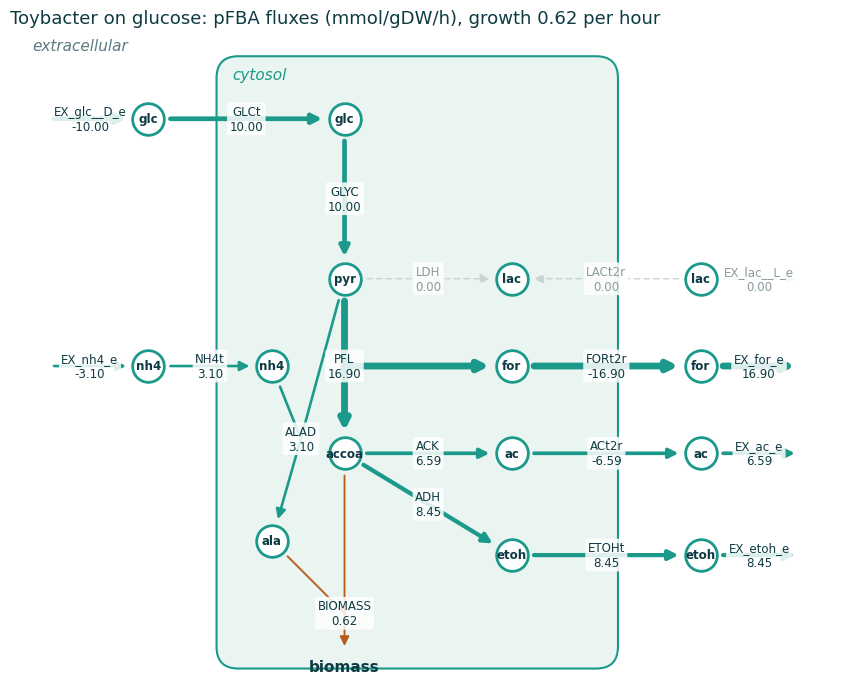

In [40]:
draw_network(model, pfba_solution.fluxes,
             title=f"Toybacter on glucose: pFBA fluxes (mmol/gDW/h), growth {pfba_solution.fluxes['BIOMASS']:.2f} per hour");

## 10 · Save, check and share  ·  5 min

SBML is the standard exchange format for models (it is what you downloaded from BiGG yesterday). A model saved as SBML can be reloaded by anyone, in any tool.

✍️ Save the model as `toybacter_fermentans.xml`.

In [42]:
cobra.io.write_sbml_model(model, "toybacter_fermentans.xml")

In [43]:
reloaded, report = cobra.io.validate_sbml_model("toybacter_fermentans.xml")
problems = {k: len(v) for k, v in report.items() if v}
print("SBML validation problems:", problems or "none")
print(f"Reloaded model: {len(reloaded.reactions)} reactions, {len(reloaded.metabolites)} metabolites, "
      f"{len(reloaded.genes)} genes; growth {reloaded.slim_optimize():.3f} per hour")

cobra.io.save_json_model(model, "toybacter_fermentans.json")   # handy for the Escher web app

SBML validation problems: none
Reloaded model: 24 reactions, 25 metabolites, 18 genes; growth 0.620 per hour


In [44]:
# ✅ Checkpoint
assert abs(reloaded.slim_optimize() - model.slim_optimize()) < 1e-9
print("✅ Saved, validated and reloaded: same model, same prediction")

✅ Saved, validated and reloaded: same model, same prediction


## Recap: you have just done a reconstruction

| What you did | Reconstruction step | In real pipelines |
|---|---|---|
| Read the annotation (§1) | Genome annotation | Prokka, RAST, eggNOG-mapper, BLAST/DIAMOND |
| Matched EC/TC numbers to ToyDB, built and corrected GPRs (§2–3) | Draft network | CarveMe, ModelSEED/KBase, gapseq, merlin, RAVEN |
| Added exchanges, diffusion and a medium (§4) | Compartments and boundary | localisation tools (PSORTb, DeepLoc), template media |
| Wrote the biomass and maintenance reactions (§5) | Biomass formulation | measured cell composition, or a template biomass |
| Checked balance, dead ends and blocked reactions (§6) | Curation and quality control | MEMOTE, cobrapy, merlin/BioISO |
| Filled the alanine gap and found its gene (§7) | Gap-filling | CarveMe, gapseq, ModelSEED |
| Compared with growth, products and knockouts (§8) | Validation | phenotype arrays (Biolog), fermentation data, Tn-seq |
| Saved SBML (§10) | Sharing | SBML files, MEMOTE reports, BiGG / BioModels |

*Toybacter* needed 18 genes and eight curation decisions: the ATP synthase subunits, the glycolysis stoichiometry, the missing ADH protons, water and ethanol diffusion, the alanine gap, the `ald` annotation and the direction of LDH. *E. coli* needed 17 years. **At 13:00** we look at how pipelines automate each of these steps; **at 14:00** you'll let ModelSEED reconstruct three real bacteria and judge the results against their curated models.

In [45]:
print(f"Final model: {len(model.reactions)} reactions, {len(model.metabolites)} metabolites, {len(model.genes)} genes")
pd.DataFrame([(r.id, r.name, r.reaction, r.gene_reaction_rule or "(no gene)") for r in model.reactions
              if not r.boundary], columns=["reaction", "name", "equation", "GPR"])

Final model: 24 reactions, 25 metabolites, 18 genes


,reaction,name,equation,GPR
0,GLCt,glucose transport (uniport),glc__D_e --> glc__D_c,TF_0001
1,GLYC,glycolysis (lumped),2.0 adp_c + glc__D_c + 2.0 nad_c + 2.0 pi_c --> 2.0 atp_c + 2.0 h2o_c + 2.0 h_c + 2.0 nadh_c + 2...,TF_0002 and TF_0003 and TF_0004
2,LDH,L-lactate dehydrogenase,h_c + nadh_c + pyr_c --> lac__L_c + nad_c,TF_0005
3,LACt2r,L-lactate transport (H+ symport),h_e + lac__L_e <=> h_c + lac__L_c,TF_0006
4,PFL,pyruvate formate-lyase,coa_c + pyr_c --> accoa_c + for_c,TF_0007 and TF_0008
5,FORt2r,formate transport (H+ symport),for_e + h_e <=> for_c + h_c,TF_0009
6,ACK,phosphotransacetylase + acetate kinase (lumped),accoa_c + adp_c + pi_c --> ac_c + atp_c + coa_c,TF_0010 and (TF_0011 or TF_0012)
7,ACt2r,acetate transport (H+ symport),ac_e + h_e <=> ac_c + h_c,TF_0013
8,ADH,acetaldehyde/alcohol dehydrogenase (lumped),accoa_c + 2 h_c + 2.0 nadh_c --> coa_c + etoh_c + 2.0 nad_c,TF_0014
9,NH4t,ammonium transport,nh4_e <=> nh4_c,TF_0015


## Extension (if you finish early): design a lactate producer

A dairy company wants *Toybacter* to secrete **lactate**. Which gene knockouts force the cell to make lactate while it still grows?

Hints:
- Knock out genes temporarily inside a `with model:` block: `model.genes.TF_0011.knock_out()`.
- Look back at the `ACK` gene rule: some genes are behind an `or`, others behind an `and`.
- This is a preview of Day 3 (strain design).

In [46]:
candidates = {"ackA": ["TF_0011"], "ackB": ["TF_0012"], "ackA + ackB": ["TF_0011", "TF_0012"],
              "pta": ["TF_0010"], "actP": ["TF_0013"], "adhE": ["TF_0014"]}
rows = []
for label, loci in candidates.items():
    with model:
        for locus in loci:
            model.genes.get_by_id(locus).knock_out()
        s = model.optimize()
        mu = s.objective_value if s.status == "optimal" and s.objective_value > 1e-9 else 0.0
        rows.append((label, round(mu, 3), round(s.fluxes["EX_lac__L_e"], 2) if mu > 0 else "no growth"))
pd.DataFrame(rows, columns=["knockout", "growth (per h)", "lactate secreted"])

,knockout,growth (per h),lactate secreted
0,ackA,0.620,0.0
1,ackB,0.620,0.0
2,ackA + ackB,0.461,14.93
3,pta,0.461,14.93
4,actP,0.461,14.93
5,adhE,0.000,no growth


<details><summary><b>Answer</b> (click to expand)</summary>

Knocking out `ackA` alone does nothing, because `ackB` takes over. Knocking out **both** acetate kinases removes the extra-ATP route, but a **single** knockout of `pta` does the same job, because `pta` sits behind an `and` in the gene rule. So does the acetate exporter `actP`. The cell then turns most of its pyruvate into lactate (about 15 mmol/gDW/h) and still grows at about 0.46 per hour, so lactate production is *coupled* to growth. Knocking out `adhE` is lethal (redox, as in §8.3). You'll meet tools that search these designs systematically on Day 3.

</details>